# Object Position / Spatial Order Matrix

This notebook explains the current region-level position-order layer. It is not a new scoring design; it documents the implementation.

Model objects in the figure:

- **Green dotted outlines** = furniture-group proxy bounds.
- **Orange dots** = expected local slots for furniture groups inside the position scope.
- **Orange lines** = residual vectors from actual furniture-group center to expected slot.
- The frame is only the local coordinate system. It helps compare positions without making rotation itself the score.

The public matrix exposes two variables: `P_position_fit` and `P_position_confidence`. The former now reads `region_position_grammar_evidence`; extent-level assembly evidence is debug-only.

## Metrics / 指标说明

The table below is intentionally short: it names the implemented row or evidence field, what it describes, what objects it touches, and how to read the value.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import HTML, SVG, display

from features.scene_loader import load_structured_svg_scene
from features.scene_evaluator import evaluate_scene, scene_position_grammar_overlay_svg

FIXTURES = [
    Path("test/SVG_baseline.svg"),
    Path("test/SVG_oblique.svg"),
    Path("test/SVG_chaoticsvg.svg"),
    Path("test/SVG_potionNoRotation.svg"),
]

POSITION_METRIC_NOTES = [
    {
        "metric": "P_position_fit",
        "describes": "Mean selected grammar fit across furniture groups.",
        "objects": "furniture groups + affordance extent centers + local slots",
        "logic": "mean(position-fit per scope)",
        "reading": "Higher means furniture groups sit close to the selected position grammar.",
    },
    {
        "metric": "P_position_confidence",
        "describes": "Reliability of the selected grammar evidence, not design quality.",
        "objects": "grammar type + group count + slot count + fit",
        "logic": "fit, count sufficiency, and slot/member agreement",
        "reading": "Higher means the proxy has enough evidence to trust its own fit score.",
    },
    {
        "metric": "position-residual-mean",
        "describes": "Average normalized distance from actual furniture-group center to expected slot.",
        "objects": "furniture-group center + slot in scope-local u/v frame",
        "logic": "mean(distance(actual, slot) / local_scale)",
        "reading": "Lower is cleaner. This is the intuitive orange-line length summary.",
    },
    {
        "metric": "position-residual-max",
        "describes": "Worst normalized group-to-slot miss inside a scope.",
        "objects": "all group residuals in one position scope",
        "logic": "max(normalized residuals)",
        "reading": "A high value means one furniture group is obviously out of the local order.",
    },
    {
        "metric": "position-grammar-type",
        "describes": "The selected order pattern: authored, pair, line, or grid.",
        "objects": "furniture-group coordinates in local u/v frame",
        "logic": "choose highest fit, lower complexity breaks ties",
        "reading": "This is evidence vocabulary, not a final design label.",
    },
]


def row_by_metric(matrix, name):
    """Find one public matrix row by metric name."""
    return next(row for row in matrix["rows"] if row["metric"] == name)


def public_position_rows(matrix):
    """Return compact public rows for the position-order family."""
    rows = [row_by_metric(matrix, "P_position_fit"), row_by_metric(matrix, "P_position_confidence")]
    return pd.DataFrame([
        {
            "metric": row["metric"],
            "view": row["view_id"],
            "score": row.get("score"),
            "status": row.get("status"),
            "method": row.get("method"),
        }
        for row in rows
    ])


def position_evidence_table(matrix):
    """Flatten nested region-position evidence into a readable table."""
    evidence = row_by_metric(matrix, "P_position_fit").get("region_position_grammar_evidence", [])
    return pd.DataFrame([
        {
            "scope": item["subject_id"],
            "scope_kind": item["subject_kind"],
            "grammar": item["position-grammar-type"],
            "fit": item["position-fit"],
            "confidence": item["position-confidence"],
            "residual_mean": item["position-residual-mean"],
            "residual_max": item["position-residual-max"],
            "members": item["position-member-count"],
            "slots": item["position-slot-count"],
            "frame_angle": item["position-frame-angle"],
        }
        for item in evidence
    ])

## Analysis Model + Current Matrix Rows

Each fixture below shows the model layer first, then the implemented metric rows/evidence. The visuals are diagnostic, not a new source of truth.

metric,describes,objects,logic,reading
P_position_fit,Mean selected grammar fit across furniture groups.,furniture groups + affordance extent centers + local slots,mean(position-fit per scope),Higher means furniture groups sit close to the selected position grammar.
P_position_confidence,"Reliability of the selected grammar evidence, not design quality.",grammar type + group count + slot count + fit,"fit, count sufficiency, and slot/member agreement",Higher means the proxy has enough evidence to trust its own fit score.
position-residual-mean,Average normalized distance from actual furniture-group center to expected slot.,furniture-group center + slot in scope-local u/v frame,"mean(distance(actual, slot) / local_scale)",Lower is cleaner. This is the intuitive orange-line length summary.
position-residual-max,Worst normalized group-to-slot miss inside a scope.,all group residuals in one position scope,max(normalized residuals),A high value means one furniture group is obviously out of the local order.
position-grammar-type,"The selected order pattern: authored, pair, line, or grid.",furniture-group coordinates in local u/v frame,"choose highest fit, lower complexity breaks ties","This is evidence vocabulary, not a final design label."


SVG_baseline.svg: P_position_fit=1.0 P_position_confidence=0.95


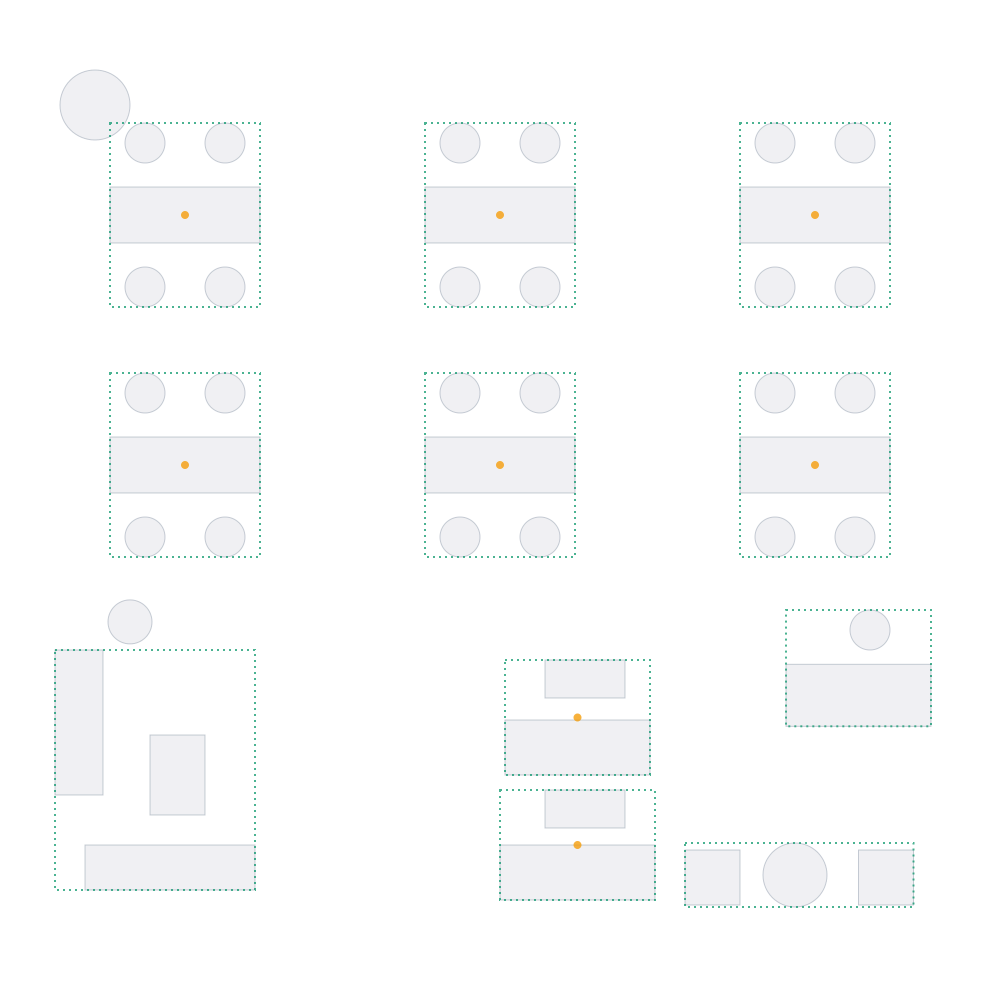

,metric,view,score,status,method
0,P_position_fit,internal_order,1.00,computed,region_position_grammar_selected_fit_mean
1,P_position_confidence,internal_order,0.95,computed,region_position_grammar_confidence_mean


,scope,scope_kind,grammar,fit,confidence,residual_mean,residual_max,members,slots,frame_angle
0,position_scope_region_center_lounge,activity_region,line,1.0,0.9,0.0,0.0,2,2,90.0
1,position_scope_region_north_tables,activity_region,grid,1.0,1.0,0.0,0.0,6,6,0.0


SVG_oblique.svg: P_position_fit=1.0 P_position_confidence=0.95


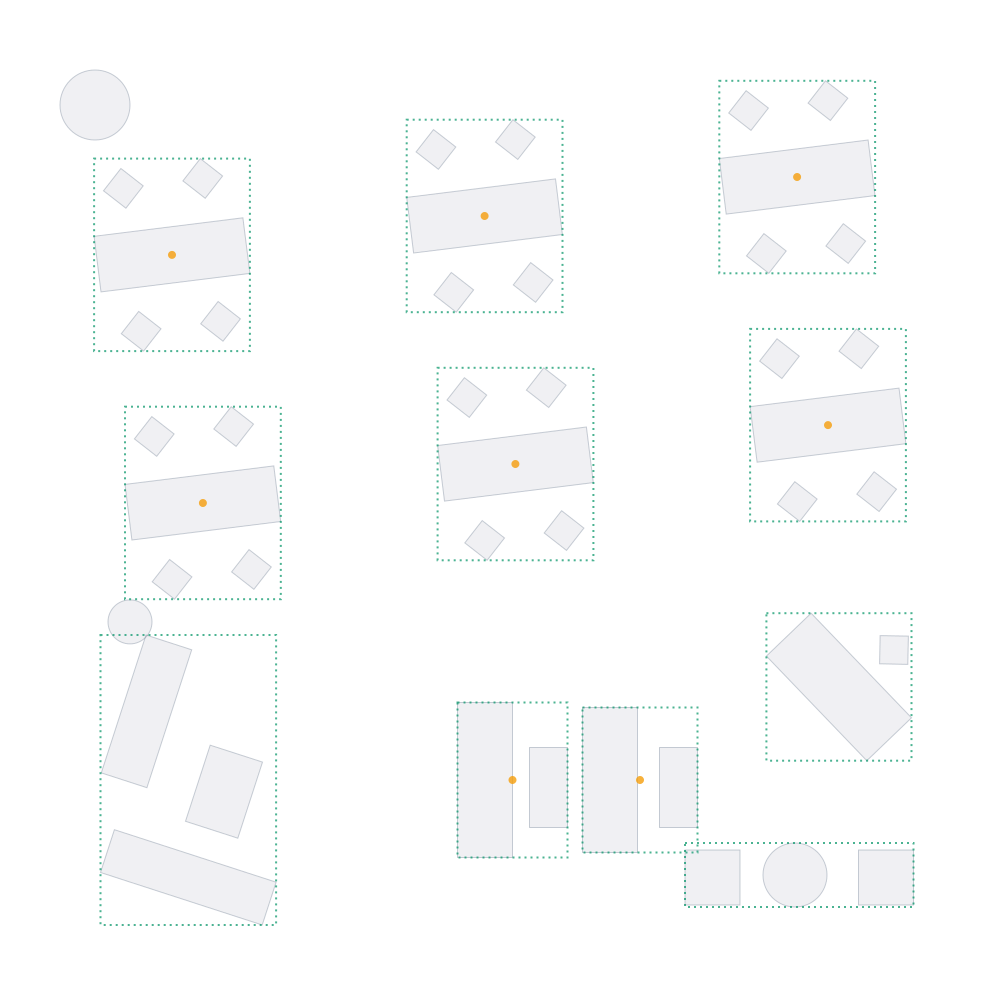

,metric,view,score,status,method
0,P_position_fit,internal_order,1.00,computed,region_position_grammar_selected_fit_mean
1,P_position_confidence,internal_order,0.95,computed,region_position_grammar_confidence_mean


,scope,scope_kind,grammar,fit,confidence,residual_mean,residual_max,members,slots,frame_angle
0,position_scope_region_center_lounge,activity_region,line,1.0,0.9,0.0,0.0,2,2,0.0000
1,position_scope_region_north_tables,activity_region,grid,1.0,1.0,0.0,0.0,6,6,172.9049


SVG_chaoticsvg.svg: P_position_fit=0.999 P_position_confidence=0.9495


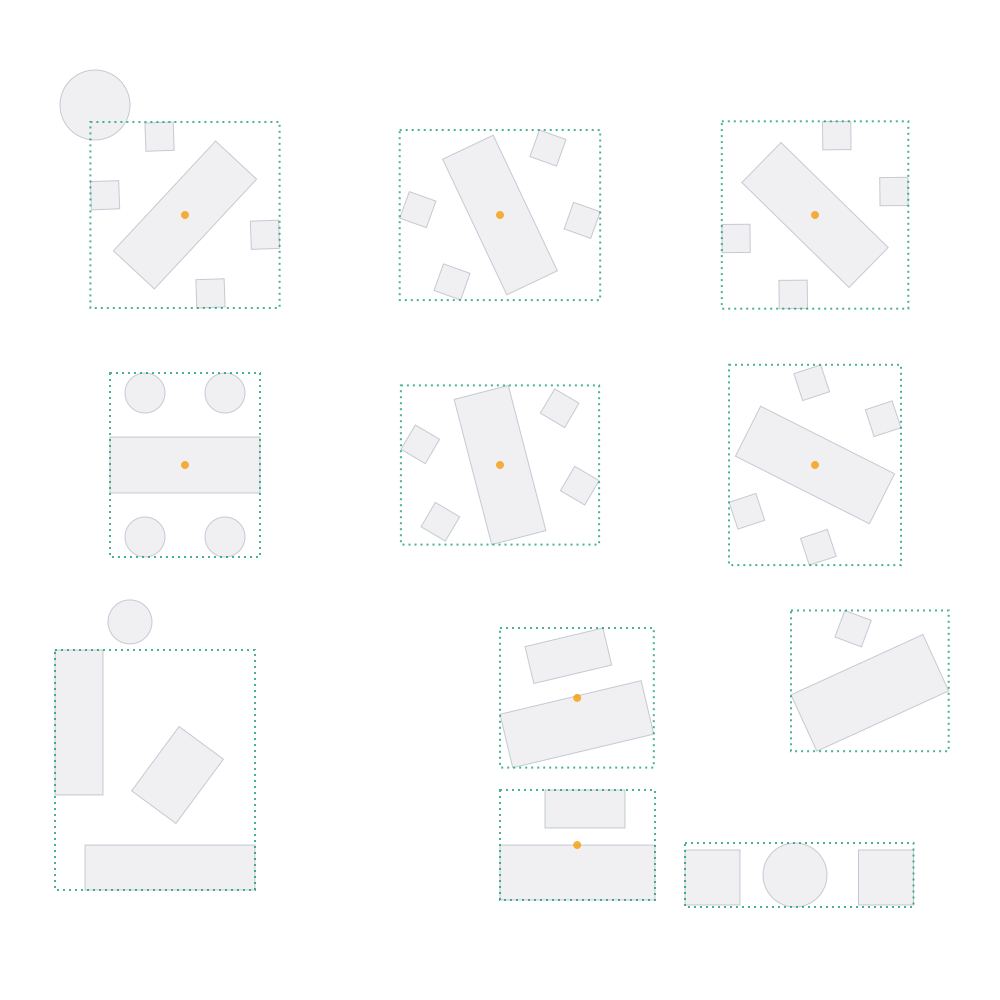

,metric,view,score,status,method
0,P_position_fit,internal_order,0.9990,computed,region_position_grammar_selected_fit_mean
1,P_position_confidence,internal_order,0.9495,computed,region_position_grammar_confidence_mean


,scope,scope_kind,grammar,fit,confidence,residual_mean,residual_max,members,slots,frame_angle
0,position_scope_region_center_lounge,activity_region,line,0.9979,0.899,0.0021,0.0021,2,2,90.0
1,position_scope_region_north_tables,activity_region,grid,1.0000,1.000,0.0000,0.0000,6,6,180.0


SVG_potionNoRotation.svg: P_position_fit=0.7088 P_position_confidence=0.8044


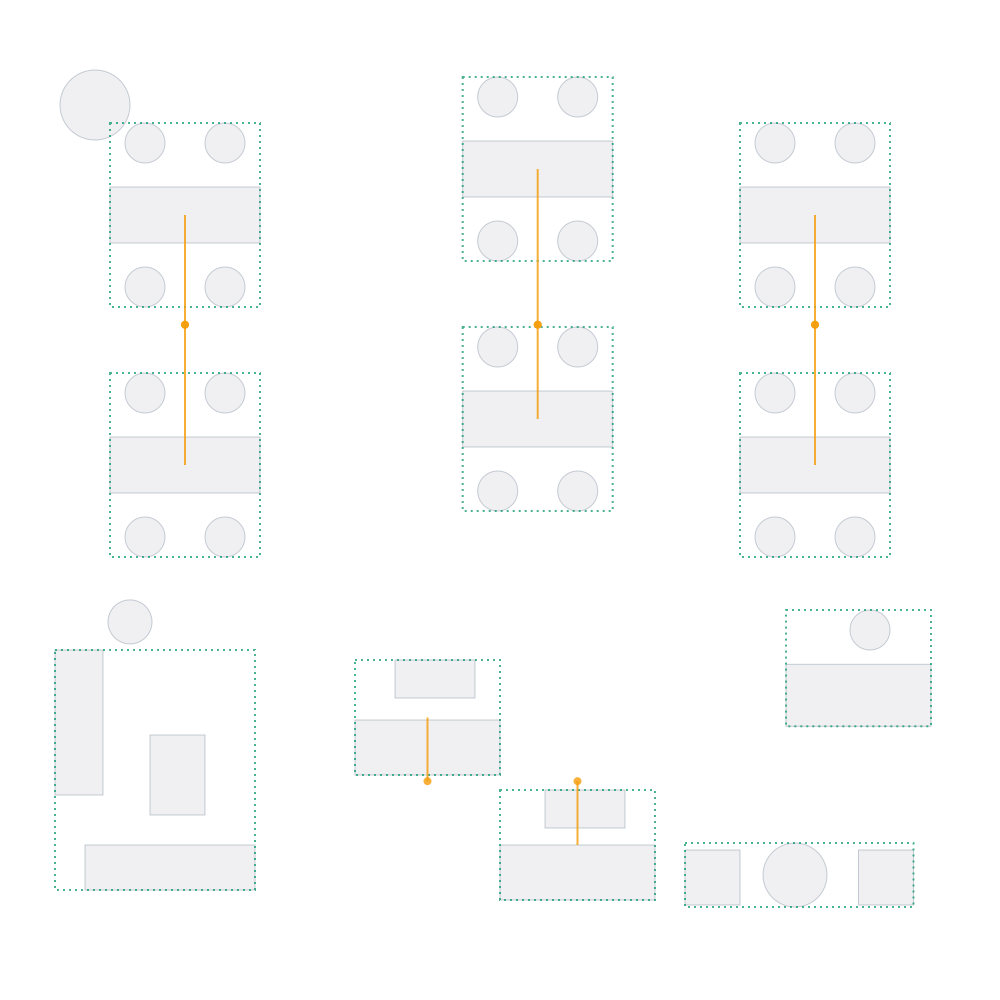

,metric,view,score,status,method
0,P_position_fit,internal_order,0.7088,computed,region_position_grammar_selected_fit_mean
1,P_position_confidence,internal_order,0.8044,computed,region_position_grammar_confidence_mean


,scope,scope_kind,grammar,fit,confidence,residual_mean,residual_max,members,slots,frame_angle
0,position_scope_region_center_lounge,activity_region,line,0.7018,0.7509,0.4250,0.4250,2,2,0.0
1,position_scope_region_north_tables,activity_region,line,0.7159,0.8580,0.3968,0.4941,6,6,0.0


In [2]:

display(HTML(pd.DataFrame(POSITION_METRIC_NOTES).to_html(index=False, escape=False)))

for path in FIXTURES:
    scene = load_structured_svg_scene(path)
    matrix = evaluate_scene(scene)
    fit = row_by_metric(matrix, "P_position_fit")
    conf = row_by_metric(matrix, "P_position_confidence")
    print(f"{path.name}: P_position_fit={fit.get('score')} P_position_confidence={conf.get('score')}")
    display(SVG(data=scene_position_grammar_overlay_svg(scene, matrix)))
    display(public_position_rows(matrix))
    display(position_evidence_table(matrix))
